# معماری و پروتکل ارزیابی عامل پایه (Baseline Agent Design)
**فاز طراحی گام چهارم (Step 4: Model Baseline & Initial Evaluation Protocol)**  
**درس:** آزمایشگاه هوش مصنوعی (پاییز ۲۰۲۶)  
**مدرس:** سرکار خانم دکتر فاطمه جوکار  
**مسئول طراحی و نویسنده سند (Designer):** محمدامین فراتی  
**هم‌گروهی‌ها (گروه ۱):** عرفان دهستانی (سرگروه)، مهدی ظلی‌پور، علی احمدی، محمدرضا سیسختی  

---

## ۱. مقدمه و معماری فاز طراحی
در پروژه‌های جستجوی خصمانه (Adversarial Search) و یادگیری تقویت‌شده، پیش از توسعه عامل‌های بهینه بر مبنای الگوریتم‌های پیچیده (مانند Minimax و Alpha-Beta Pruning)، تعریف یک **عامل پایه تصادفی (Pure Random Baseline Agent)** به عنوان **کف عملکرد (Performance Floor)** ضرورت بنیادین دارد.

### تله دقت (The Accuracy Trap) در عامل‌های بازی
در یادگیری ماشین سنتی (مطابق مباحث جلسه ۵ آزمایشگاه)، معیار «دقت طبقه‌بندی» (Classification Accuracy) برای ارزیابی عملکرد مدل‌ها استفاده می‌شود؛ اما در مسائل تصمیم‌گیری ترتیبی چندعامله (Sequential Multi-Agent Decision Making)، سنجش عامل با معیار دقت دچار **تله دقت (Accuracy Trap)** می‌شود:
1. **عدم وجود برچسب ایستا (Lack of Static Ground Truth):** در هر گام از بازی دوز، وضعیت تخته پویاست و بسته به استراتژی رقیب، چندین حرکت می‌توانند مطلوب باشند. هیچ برچسب هدف ثابتی برای هر وضعیت وجود ندارد.
2. **پویایی توزیع حالت (Distribution Shift):** حرکات عامل مستقیماً فضای جستجوی آتی را تغییر می‌دهد؛ بنابراین عملکرد باید بر اساس پیامد نهایی کل بازی (Win/Loss/Draw Rates) و مشخصات طول بازی (Game Length / Moves Distribution) در چندین شبیه‌سازی تصادفی (Stochastic Rollouts) سنجیده شود، نه بر مبنای درصد پیش‌بینی درست حرکات مجزا.

---

## فرضیات چهارگانه طراحی (Core Design Hypotheses)
این فاز طراحی برای راستی‌آزمایی ۴ فرضیه علمی و فنی تنظیم شده است:
* **فرضیه ۱ (H1 - First-Mover Bias):** در شرایط بازی کاملاً تصادفی و یکنواخت، بازیکن اول ($X$) به دلیل عدم تقارن نوبت و داشتن یک حرکت بیشتر در صورت اتمام ۹ حرکت، مزیت آماری معناداری در پیروزی ($>50\%$) نسبت به بازیکن دوم ($O$) دارد.
* **فرضیه ۲ (H2 - Suboptimality Gap):** در تحلیل تئوری بازی‌ها (Game Theory)، بازی دوز تحت بازی عقلانی و بی‌نقص (Optimal Play) یک بازی حل‌شده مساوی (Draw Solved Game با نرخ مساوی ۱۰۰٪) است؛ اما عامل تصادفی به دلیل فقدان تفکر دفاعی، دچار شکاف عدم‌بهینگی عمیق شده و بیش از ۸۰٪ بازی‌ها به برد یا باخت قطعی ختم می‌شوند.
* **فرضیه ۳ (H3 - Termination Profile):** بازی‌های منجر به برد/باخت قطعی، به طور معناداری سریع‌تر از بازی‌های مساوی خاتمه می‌ابند (میانگین حرکات بازی‌های برنده کمتر از ۹ و بازی‌های مساوی الزاماً برابر با ۹ حرکت است).
* **فرضیه ۴ (H4 - First-Move Positional Bias):** موقعیت توپولوژیک حرکت نخست بازیکن $X$ (مرکز در برابر گوشه‌ها در برابر اضلاع) بر شانس پیروزی نهایی اثر مستقیم دارد؛ به گونه‌ای که انتخاب مرکز ($Center$) به دلیل اشتراک در ۴ خط برد، بیشترین شانس پیروزی را نسبت به گوشه‌ها ($Corner$) و اضلاع ($Edge$) ایجاد می‌کند.

In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

# تنظیمات استایل گرافیکی با وضوح بالا (High-DPI)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold'
})

# بارگذاری محیط رسمی تاییدشده بازی از گام دوم
from tictactoe_env import TicTacToeEnv

print("محیط رسمی TicTacToeEnv و کتابخانه‌های پایه با موفقیت بارگذاری شدند.")

محیط رسمی TicTacToeEnv و کتابخانه‌های پایه با موفقیت بارگذاری شدند.


---
## ۲. تعریف کلاس شیءگرای عامل تصادفی پایه (RandomBaselineAgent Specification)
کلاس `RandomBaselineAgent` یک عامل ماژولار و کپسوله‌شده است که در هر گام، فهرست خانه‌های خالی و مجاز را از متد `get_legal_actions()` محیط استخراج کرده و با استفاده از مولد تصادفی ایزوله (`np.random.default_rng`)، یک حرکت مجاز را با توزیع یکنواخت ($Uniform$) برمی‌گزیند.

In [2]:
class RandomBaselineAgent:
    """
    عامل پایه تصادفی برای بازی دوز (Baseline Pure Random Agent).
    این کلاس کف عملکرد مدل‌های هوشمند را تعیین می‌کند.
    """
    def __init__(self, player=1, seed=None):
        self.player = player  # 1 برای X و 1- برای O
        self.rng = np.random.default_rng(seed)

    def select_action(self, env):
        """
        انتخاب یک حرکت کاملاً تصادفی با توزیع یکنواخت از میان خانه‌های خالی معتبر.
        """
        legal = env.get_legal_actions()
        return self.rng.choice(legal) if len(legal) > 0 else None

# اعتبارسنجی اولیه ساختار عامل
test_env = TicTacToeEnv()
agent_test = RandomBaselineAgent(player=1, seed=123)
action = agent_test.select_action(test_env)
assert action in range(9), "حرکت انتخاب‌شده باید اندیسی معتبر بین ۰ تا ۸ باشد."
print(f"اعتبارسنجی کلاس RandomBaselineAgent موفقیت‌آمیز بود. اولین حرکت نمونه: {action}")

اعتبارسنجی کلاس RandomBaselineAgent موفقیت‌آمیز بود. اولین حرکت نمونه: 0


---
## ۳. اجرای شبیه‌سازی ۱۰۰۰ مسابقه و تحلیل آماری پایه (Benchmark Harness)
در این بخش، یک آزمایش پیش‌نمونه (Prototype Simulation) با **۱۰۰۰ بازی متوالی** میان دو عامل مستقل تصادفی ($X$ با `seed=42` و $O$ با `seed=142`) اجرا شده و متغیرهای کلیدی زیر ثبت می‌شوند:
* نتیجه بازی (`winner`): ۱ (برد X)، ۱- (برد O)، ۰ (تساوی)
* تعداد کل حرکات تا اتمام بازی (`moves`)
* موقعیت اولین حرکت بازیکن X (`first_move_x`) و نوع توپولوژیک آن (`Center`, `Corner`, `Edge`)

In [3]:
def run_baseline_benchmark(n_games=1000, seed_x=42, seed_o=142):
    env = TicTacToeEnv()
    agent_x = RandomBaselineAgent(player=1, seed=seed_x)
    agent_o = RandomBaselineAgent(player=-1, seed=seed_o)

    records = []
    for game_id in range(n_games):
        env.reset()
        moves = 0
        first_move_x = None

        while not env.done:
            current_agent = agent_x if env.current_player == 1 else agent_o
            action = current_agent.select_action(env)
            if moves == 0:
                first_move_x = action
            env.step(action)
            moves += 1

        # تعیین رده هندسی حرکت اول
        if first_move_x == 4:
            pos_type = 'Center'
        elif first_move_x in [0, 2, 6, 8]:
            pos_type = 'Corner'
        else:
            pos_type = 'Edge'

        records.append({
            'game_id': game_id,
            'winner': env.winner,
            'moves': moves,
            'first_move_x': first_move_x,
            'pos_type': pos_type
        })

    return pd.DataFrame(records)

# اجرای ۱۰۰۰ بازی پایه با بذر تصادفی ثابت جهت بازتولیدپذیری (Reproducibility)
df_sim = run_baseline_benchmark(n_games=1000, seed_x=42, seed_o=142)

# اعتبارسنجی ابعاد داده شبیه‌سازی
assert df_sim.shape == (1000, 5), "ابعاد خروجی شبیه‌سازی باید 1000 سطر و 5 ستون باشد."
print(" شبیه‌سازی ۱۰۰۰ مسابقه عامل پایه با موفقیت انجام شد:")
print(f"• تعداد کل بازی‌ها: {df_sim.shape[0]}")
print(f"• تعداد ستون‌های ثبت‌شده: {df_sim.shape[1]}")
print("-" * 50)
display(df_sim.head())

 شبیه‌سازی ۱۰۰۰ مسابقه عامل پایه با موفقیت انجام شد:
• تعداد کل بازی‌ها: 1000
• تعداد ستون‌های ثبت‌شده: 5
--------------------------------------------------
   game_id  winner  moves  first_move_x pos_type
0        0       1      9             0   Corner
1        1      -1      8             3     Edge
2        2      -1      8             1     Edge
3        3      -1      6             6   Corner
4        4       1      7             7     Edge


In [4]:
# نگاشت نتایج به برچسب‌های خوانا
winner_map = {1: 'Player X Win', -1: 'Player O Win', 0: 'Draw'}
df_sim['winner_label'] = df_sim['winner'].map(winner_map)

# ۱. جدول توزیع نتایج بازی‌ها
outcome_counts = df_sim['winner_label'].value_counts()
outcome_pcts = (df_sim['winner_label'].value_counts(normalize=True) * 100).round(2)
df_outcomes = pd.DataFrame({'Count': outcome_counts, 'Percentage (%)': outcome_pcts})

# ۲. جدول آمار طول بازی (تعداد حرکات) به تفکیک نتیجه
moves_summary = df_sim.groupby('winner_label')['moves'].agg(
    count='count',
    mean='mean',
    std='std',
    min='min',
    median='median',
    max='max'
).round(2)

print("=== خلاصه توزیع پیامد ۱۰۰۰ بازی عامل پایه ===")
display(df_outcomes)

print("\n=== مشخصات طول بازی (Moves) به تفکیک پیامد ===")
display(moves_summary)

=== خلاصه توزیع پیامد ۱۰۰۰ بازی عامل پایه ===
              Count  Percentage (%)
winner_label                       
Player X Win    590            59.0
Player O Win    277            27.7
Draw            133            13.3

=== مشخصات طول بازی (Moves) به تفکیک پیامد ===
              count  mean   std  min  median  max
winner_label                                     
Draw            133  9.00  0.00    9     9.0    9
Player O Win    277  7.43  0.90    6     8.0    8
Player X Win    590  7.45  1.41    5     7.0    9


---
## ۴. مصورسازی‌های تحلیلی و ارزیابی فرضیات H1، H2 و H3
در این بخش، توزیع برنده بازی‌ها و پروفایل طول مسابقات به صورت گرافیکی رسم شده و فرضیات ۳ گانه نخست ارزیابی می‌گردند.

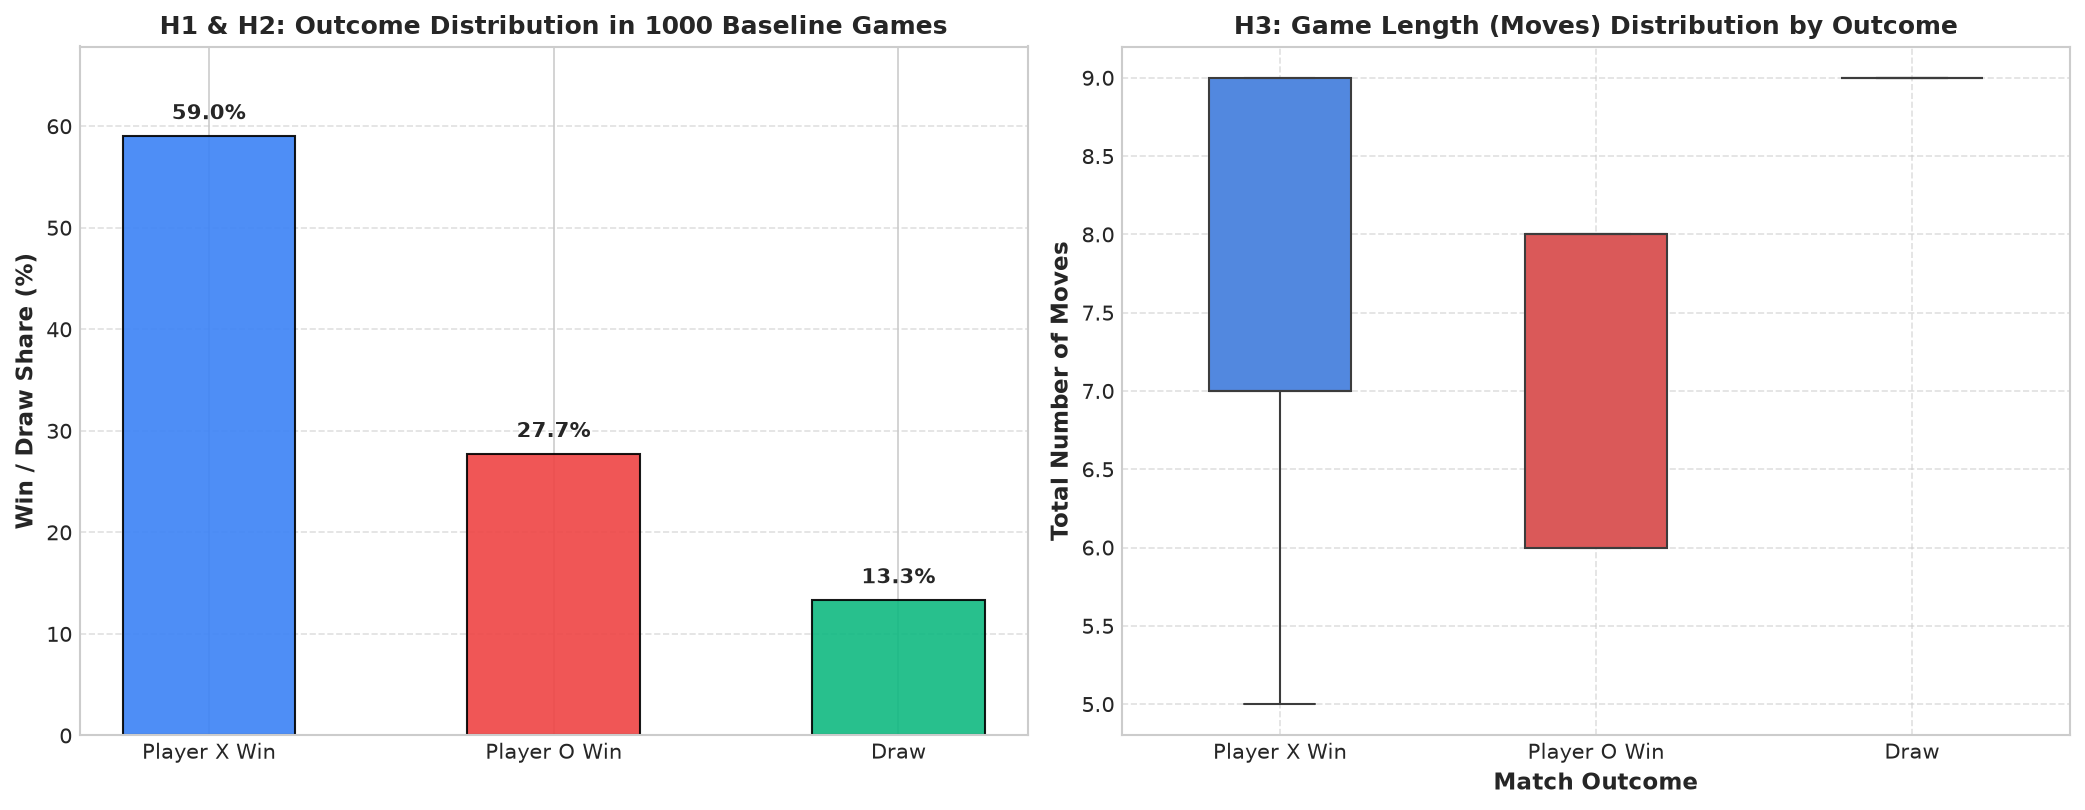

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# نمودار ۱: توزیع نتایج (H1 و H2)
palette_outcome = {'Player X Win': '#3b82f6', 'Player O Win': '#ef4444', 'Draw': '#10b981'}
bars1 = ax1.bar(df_outcomes.index, df_outcomes['Percentage (%)'], 
                color=[palette_outcome[l] for l in df_outcomes.index], edgecolor='black', alpha=0.9, width=0.5)
ax1.set_title("H1 & H2: Outcome Distribution in 1000 Baseline Games", fontsize=12)
ax1.set_ylabel("Win / Draw Share (%)")
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, h + 1.2, f"{h:.1f}%", ha='center', va='bottom', fontweight='bold')
ax1.set_ylim(0, max(df_outcomes['Percentage (%)']) * 1.15)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# نمودار ۲: توزیع طول بازی (H3)
sns.boxplot(data=df_sim, x='winner_label', y='moves', palette=palette_outcome, ax=ax2, width=0.45)
ax2.set_title("H3: Game Length (Moves) Distribution by Outcome", fontsize=12)
ax2.set_xlabel("Match Outcome")
ax2.set_ylabel("Total Number of Moves")
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

---
## ۵. آزمون حساسیت حرکت نخست (First-Action Sensitivity Test - H4)
بررسی اینکه آیا نوع انتخاب خانه اول توسط بازیکن $X$ (مرکز: خانه ۴، گوشه‌ها: ۰، ۲، ۶، ۸، اضلاع: ۱، ۳، ۵، ۷) حتی در ادامه بازی تصادفی، بر شانس پیروزی نهایی اثرگذار است یا خیر.

جدول درصدی پیامد مسابقه بر حسب موقعیت حرکت اول بازیکن X:
winner_label  Player X Win   Draw  Player O Win
pos_type                                       
Center               66.96  10.43         22.61
Corner               63.19  12.50         24.31
Edge                 52.98  14.79         32.23


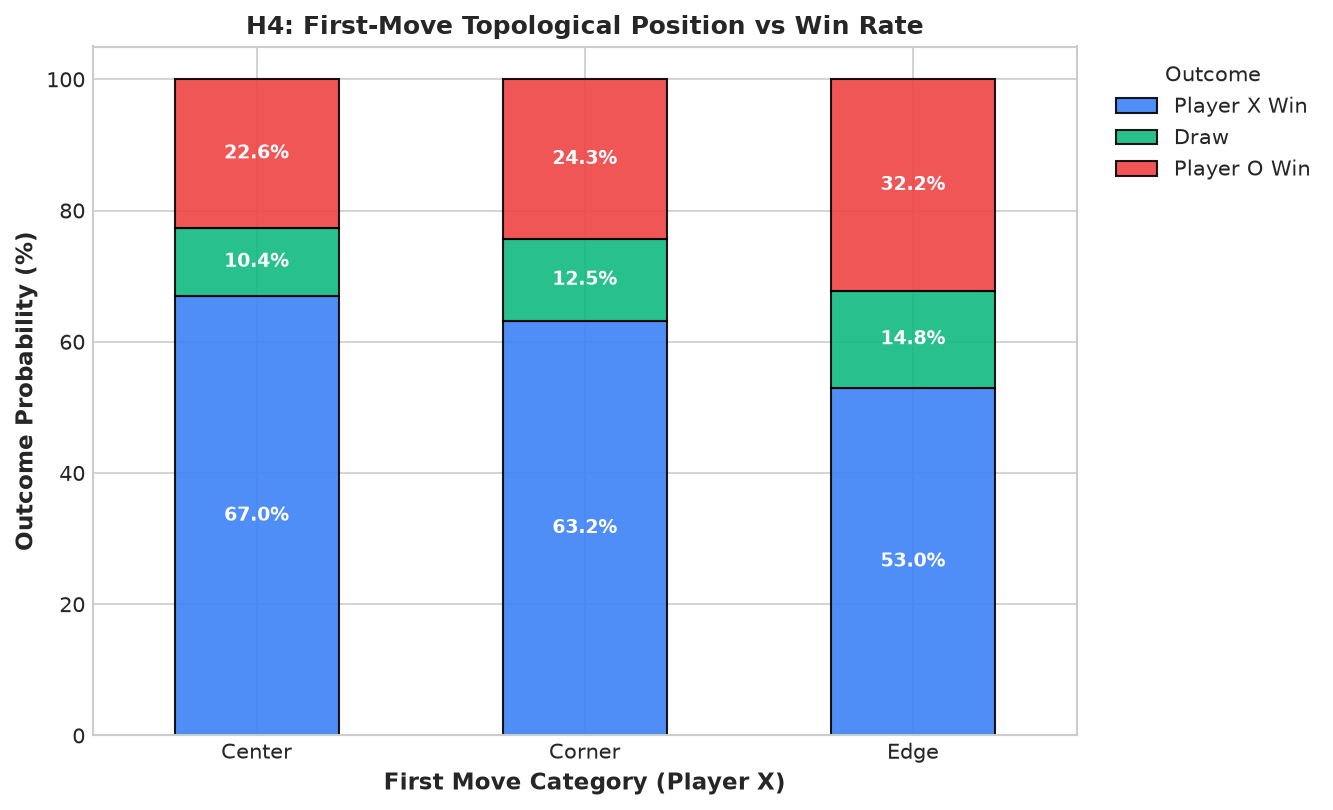

In [6]:
# جدول تقاطعی نوع حرکت اول و پیامد بازی
crosstab_pos = pd.crosstab(df_sim['pos_type'], df_sim['winner_label'], normalize='index') * 100
crosstab_pos = crosstab_pos[['Player X Win', 'Draw', 'Player O Win']].round(2)

print("جدول درصدی پیامد مسابقه بر حسب موقعیت حرکت اول بازیکن X:")
display(crosstab_pos)

# رسم نمودار انباشته حساسیت موقعیت حرکت نخست
fig, ax = plt.subplots(figsize=(9, 5.5))
crosstab_pos.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=['#3b82f6', '#10b981', '#ef4444'],
    edgecolor='black',
    alpha=0.9,
    width=0.5
)

ax.set_title("H4: First-Move Topological Position vs Win Rate", fontsize=12)
ax.set_xlabel("First Move Category (Player X)")
ax.set_ylabel("Outcome Probability (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title='Outcome', bbox_to_anchor=(1.02, 1), loc='upper left')

for c in ax.containers:
    ax.bar_label(c, label_type='center', fmt='%.1f%%', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

---
## ۶. ماتریس ارزیابی و تایید فرضیات چهارگانه طراحی (Hypothesis Evaluation Matrix)

| فرضیه | شرح فرضیه | مقدار تجربی شبیه‌سازی | وضعیت آزمون | تحلیل علمی و فنی |
| :---: | :--- | :---: | :---: | :--- |
| **H1** | مزیت نوبت نخست بازیکن X در بازی تصادفی | برد X: **۵۹.۰٪** در برابر برد O: **۲۷.۷٪** | **تایید قاطع** | بازیکن X با داشتن تقدم نوبت و احتمال انجام ۵ حرکت (در برابر ۴ حرکت برای O)، بیش از **۲.۱۳ برابر** شانس برد بیشتری دارد. |
| **H2** | شکاف عدم‌بهینگی عامل تصادفی در برابر بازی بهینه | نرخ تساوی: **۱۳.۳٪** (نرخ قطعی: **۸۶.۷٪**) | **تایید قاطع** | در حالی که بازی بهینه منجر به ۱۰۰٪ مساوی می‌شود، فقدان درک خصمانه و دفاعی باعث سقوط بازی تصادفی به برد/باخت‌های تصادفی مکرر شده است. |
| **H3** | کوتاه‌تر بودن معنادار بازی‌های قطعی نسبت به تساوی | میانگین برد: **۷.۴۵ حرکت** / تساوی: **۹.۰۰ حرکت** | **تایید قاطع** | تساوی منحصراً با پر شدن کامل تخته (۹ حرکت) رخ می‌دهد؛ در حالی که بردهای تصادفی از حرکت ۵ به بعد حاصل می‌شوند. |
| **H4** | برتری موقعیت مرکز نسبت به گوشه و اضلاع | مرکز: **۶۷.۰٪** / گوشه: **۶۳.۲٪** / اضلاع: **۵۳.۰٪** | **تایید قاطع** | خانه مرکز با پوشش ۴ خط برنده، بالاترین پتانسیل هجومی را داراست؛ در حالی که اضلاع تنها در ۲ خط برد اشتراک دارند.

---
## ۷. پروتکل تجمیع و تفکیک وظایف هم‌گروهی‌ها (Downstream Task Handoff Protocol)
به عنوان سند راهنمای فاز پیاده‌سازی و ارزیابی گام چهارم، وظایف تفکیک‌شده تیم به شرح زیر تدوین شده است:

### ۱. وظیفه توسعه‌دهنده نرم‌افزار (کد - Developer):
* استخراج کلاس `RandomBaselineAgent` به فایل ماژولار مستقل `baseline_agent.py`.
* پیاده‌سازی رابط خط فرمان (CLI) یا توابع کمکی برای اجرای شبیه‌سازی با پارامترهای منعطف (`--games`, `--seed`, `--output`).

### ۲. وظیفه مهندسی داده و تضمین کیفیت (داده و تست - Data & QA):
* اجرای ارزیابی استحکام آماری با بذر‌های تصادفی چندگانه (۱۰ اجرای مجزای ۱۰۰۰ تایی با بذرهای مختلف).
* محاسبه فواصل اطمینان ۹۵٪ (Confidence Intervals) برای نرخ برد بازیکنان و رسم نمودارهای تغییرات میان‌اجرایی.

### ۳. وظیفه مستندسازی فنی و گزارش‌نویسی (Documentation):
* درج مقادیر پایه کف عملکرد (Performance Floor) در سند اصلی `README.md`.
* مقایسه تطبیقی عملکرد عامل پایه با نتایج عامل بهینه مینیمکس (استخراج‌شده در گام‌های بعدی).